# Solar filament instance segmentation: the final pipeline

This notebook walks through the submitted pipeline (Kaggle submission 57348584) on one supplied test image,
running each stage with the released weights and the same code as the full run, then shows how to rebuild
all 180 test predictions with one command.

**Pipeline.** Five model families are trained on each of five date-grouped folds: YOLO11m-seg at 1536 px,
Mask R-CNN (ResNet-50 FPN v2) at 1536 px, YOLO11m-seg at 2048 px, YOLO26m-seg at 1536 px, and a spine-aware
dense ConvNeXt-Small U-Net at native resolution. For each fold:
1. **TTA.** Every model predicts all eight dihedral views of the image.
2. **Instance fusion.** Candidates from all views and families are clustered by mask IoU and fused by pixel
   voting; each pixel is owned by one instance.
3. **Crop refinement.** A cross-fitted ResNet-34 U-Net redraws each fused mask from an image crop.
4. **Rescoring.** A gradient-boosted rescorer, trained on out-of-fold instances, scores the refined instances.

The five fold ensembles are then fused once more (level 2) and thresholded.

**Results.** Pooled five-fold out-of-fold PQ is 0.47467 (organizer scorer: IoU > 0.5, counts pooled over every
annotator record); public leaderboard 0.41. Inference uses only the supplied test image. No MAGFiLO or other
external annotations are used.

In [1]:
import importlib.util, json, logging, pickle, sys, time
from argparse import Namespace
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from pycocotools import mask as mask_utils

REPOSITORY = Path.cwd()
sys.path[:0] = [str(REPOSITORY / 'src'), str(REPOSITORY / 'infra')]
from solar_filament.coco import CocoIndex
from solar_filament.metrics import reference_counts
from solar_filament.storage import annotations_path, dataset_root, storage_root
from solar_filament.submission import validate_predictions

def load(name):
    spec = importlib.util.spec_from_file_location(name.replace('-', '_'), REPOSITORY / 'infra' / f'{name}.py')
    module = importlib.util.module_from_spec(spec)
    sys.modules[spec.name] = module
    spec.loader.exec_module(module)
    return module

tta, ensemble, refine = load('tta-inference'), load('ensemble-test'), load('refine-masks')
root = storage_root()                      # SOLAR_STORAGE_ROOT
WEIGHTS = root / 'weights' / 'final'       # the downloaded Kaggle dataset notoverkil/solar-filament-weights
WORK = root / 'runs' / 'notebook-demo'
manifest = json.loads((WEIGHTS / 'manifest.json').read_text())
print('CUDA:', torch.cuda.get_device_name() if torch.cuda.is_available() else 'not available')
print(len(manifest['models']), 'fold models;', len(manifest['files']), 'released files')

CUDA: NVIDIA GeForce RTX 4060 Laptop GPU
25 fold models; 59 released files


## Data and validation

The supplied training set has 707 physical images with 1,154 annotator records: an image can carry one, two
or three independent drawings. The organizer's PQ scores one prediction set against every annotator record
separately and pools the counts. Folds keep every record of an image, and all images from the same UTC date,
together, so no observation is split between training and validation.

In [2]:
index = CocoIndex(annotations_path(root))
annotators = pd.Series({name: len(records) for name, records in index.images_by_filename.items()})
print('physical images:', len(annotators), '| annotator records:', int(annotators.sum()),
      '| annotations:', len(index.data['annotations']))
print('images by annotator count:', annotators.value_counts().sort_index().to_dict())
folds = pd.read_csv(WEIGHTS / 'splits' / 'folds.csv')
assert folds.groupby('capture_date').fold.nunique().max() == 1
folds.groupby('fold').agg(images=('filename', 'nunique'), records=('annotator_records', 'sum'))

physical images: 707 | annotator records: 1154 | annotations: 8199
images by annotator count: {1: 411, 2: 145, 3: 151}


,images,records
fold,,
0,141,230
1,141,229
2,142,231
3,142,233
4,141,231


## The metric

A prediction matches an annotated filament when IoU > 0.5; PQ = (sum of matched IoU) / (TP + FP/2 + FN/2), with
counts pooled across every annotator-image record. In this toy example two of three annotated objects are matched
(IoU 0.6 and 0.8), so PQ = 1.4 / (2 + 0.5 + 0.5).

In [3]:
toy = np.array([[0.6, 0.0], [0.0, 0.8], [0.3, 0.0]])   # rows: annotated objects, columns: predictions
reference_counts(toy).scores()

{'tp': 2,
 'fp': 0,
 'fn': 1,
 'sum_iou': 1.4,
 'pq': 0.5599999999999999,
 'sq': 0.7,
 'rq': 0.8}

## The released models

Each fold model is a folder with its training configuration and inference-only weights (exponential moving
average). The table lists fold 0's five families; folds 1 to 4 repeat them, each trained without its own
held-out fold.

In [4]:
rows = []
for model in manifest['models']:
    config = yaml.safe_load((WEIGHTS / model['run'] / 'config.yaml').read_text())
    rows.append({'fold': model['fold'], 'family': model['family'], 'run': model['run'], 'input': config.get('image_size', 'native crops'),
                 'epochs': config['epochs']})
models = pd.DataFrame(rows)
models[models.fold == 0]

,fold,family,run,input,epochs
0,0,yolo11m-1536,p1-yolo11m1536-long-f0,1536,60
1,0,maskrcnn-1536,p1-maskrcnn1536-long-f0,1536,36
2,0,yolo11m-2048,p3-yolo11m2048-e60-f0,2048,60
3,0,yolo26m-1536,p3-yolo26m1536-e60-f0,1536,60
4,0,dense-convnext-small,p4-dense-convnexts1024-f0,native crops,80


## Stage 1: eight-view TTA for every fold model

All 25 fold models predict the eight dihedral views of one test image. Each candidate keeps its score and its
native-resolution mask, mapped back to the original orientation.

In [5]:
test_images = sorted((dataset_root(root) / 'test/test_images').glob('*.jpeg'))
image_path = next(path for path in test_images if path.stem == '20140420195854Bh')   # most submitted filaments (17)
stem = image_path.stem
image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
from ultralytics.utils import LOGGER
LOGGER.setLevel(logging.ERROR)   # hide Ultralytics deprecation notices
options = Namespace(candidate_threshold=0.05, maximum_candidates=100, low_mask_threshold=0.3, image_size=None)

def source_for(model):
    folder = WEIGHTS / model['run']
    if model['tta_family'] == 'maskrcnn':
        return tta.MaskRCNNSource(folder, 'final', options)
    if model['tta_family'] == 'dense':
        return tta.DenseSource(folder, options)
    return tta.YoloSource(folder, 'final', options)

counts, started = {}, time.time()
for model in manifest['models']:
    source = source_for(model)
    records = [record for view in manifest['views'] for record in source(image, view)]
    target = WORK / 'tta' / model['run'] / 'candidates'
    target.mkdir(parents=True, exist_ok=True)
    if hasattr(source, 'finish'):
        source.finish(target.parent, stem)
    (target / f'{stem}.json').write_text(json.dumps(records))
    counts[(model['fold'], model['family'])] = len(records)
    del source
    torch.cuda.empty_cache()
print(f'{stem}: TTA for 25 models in {time.time() - started:.0f} s')
pd.Series(counts).unstack()

20140420195854Bh: TTA for 25 models in 278 s


,dense-convnext-small,maskrcnn-1536,yolo11m-1536,yolo11m-2048,yolo26m-1536
0,182,416,368,428,386
1,169,417,435,450,389
2,177,442,396,485,395
3,186,429,392,394,401
4,167,435,428,414,433


## Stage 2: instance fusion within each fold (level 1)

Within a fold, candidates from the 40 sources (5 families × 8 views) are clustered greedily by mask IoU ≥ 0.5,
with at most one member per source. A fused mask keeps pixels drawn by at least half of its members. Its score
is the mean member score over all sources, so a source that missed the instance contributes zero. Pixels are
then owned in score order, and the instance features for the rescorer are computed.

In [6]:
setting = tuple(manifest['level1_setting'][key] for key in ('cluster_iou', 'pixel_vote', 'minimum_area', 'maximum_detections'))
level1 = {}
for fold in sorted(models.fold.unique()):
    directories = [WORK / 'tta' / run / 'candidates' for run in models[models.fold == fold].run]
    _, rows = ensemble.fold_instances((directories, stem, setting, manifest['views']))
    level1[fold] = pd.DataFrame(rows)
{fold: len(frame) for fold, frame in level1.items()}

{np.int64(0): 68,
 np.int64(1): 67,
 np.int64(2): 64,
 np.int64(3): 66,
 np.int64(4): 66}

## Stage 3: crop refinement and adoption

Each fused instance is cropped from the native image with context, and the five refiner fold models, averaged,
redraw its mask from the image and the fused mask. The refined masks then replace the fused ones and are
re-owned in fused order (instances below 150 px are dropped). The `matched` figure it prints is the share of
annotators who drew each instance, which is 0 here because test images carry no labels.

In [7]:
refiners, size = refine.load_models(WEIGHTS / 'refiner', 'cuda')
tables = WORK / 'level1'
tables.mkdir(parents=True, exist_ok=True)
for fold, frame in level1.items():
    inputs, _, _, boxes = refine.extract(frame, size, workers=1, with_targets=False)
    probabilities = refine.predict_crops(refiners, inputs, 'cuda', 64)
    refine.add_refined_columns(frame, probabilities, None, boxes)
    frame.to_csv(tables / f'level1-f{fold}.csv', index=False)
refine.adopt(Namespace(source=tables, pattern='level1-f*.csv', column=manifest['refiner']['column'],
                       minimum_area=manifest['refiner']['minimum_area'], output=WORK / 'adopted', workers=1))
adopted = {fold: pd.read_csv(WORK / 'adopted' / f'level1-f{fold}.csv') for fold in level1}

level1-f0.csv: 68 -> 63 instances, matched 0.0000


level1-f1.csv: 67 -> 63 instances, matched 0.0000


level1-f2.csv: 64 -> 59 instances, matched 0.0000


level1-f3.csv: 66 -> 62 instances, matched 0.0000


level1-f4.csv: 66 -> 62 instances, matched 0.0000


## Stage 4: rescoring and fusion across folds (level 2)

The rescorer (gradient-boosted trees fitted on out-of-fold instances of all five folds) gives each refined instance
the probability that the annotators drew it. The five fold ensembles are fused once more: an instance missed by a
fold contributes zero. Pixels are owned in probability order, and instances below the out-of-fold threshold
are dropped.

In [8]:
saved = pickle.loads((WEIGHTS / 'rescorer-hgb.pkl').read_bytes())
rows = []
for fold, frame in adopted.items():
    frame['probability'] = saved['rescorer'].predict(frame)
    frame['fold'] = fold
    rows += frame[['stem', 'fold', 'probability', 'rle']].to_dict('records')
_, masks, owned = ensemble.combine((stem, rows, len(adopted), setting[0], setting[1], setting[2], manifest['threshold']))
validation = validate_predictions({stem: masks}, {stem})
print(f'{owned} owned instances, {len(masks)} above threshold {manifest["threshold"]}')
validation

86 owned instances, 17 above threshold 0.3


{'expected_images': 1,
 'images_with_predictions': 1,
 'images_without_predictions': [],
 'filament_rows': 17,
 'minimum_area': 363,
 'maximum_area': 3770,
 'overlapping_instances': 0,
 'empty_instances': 0}

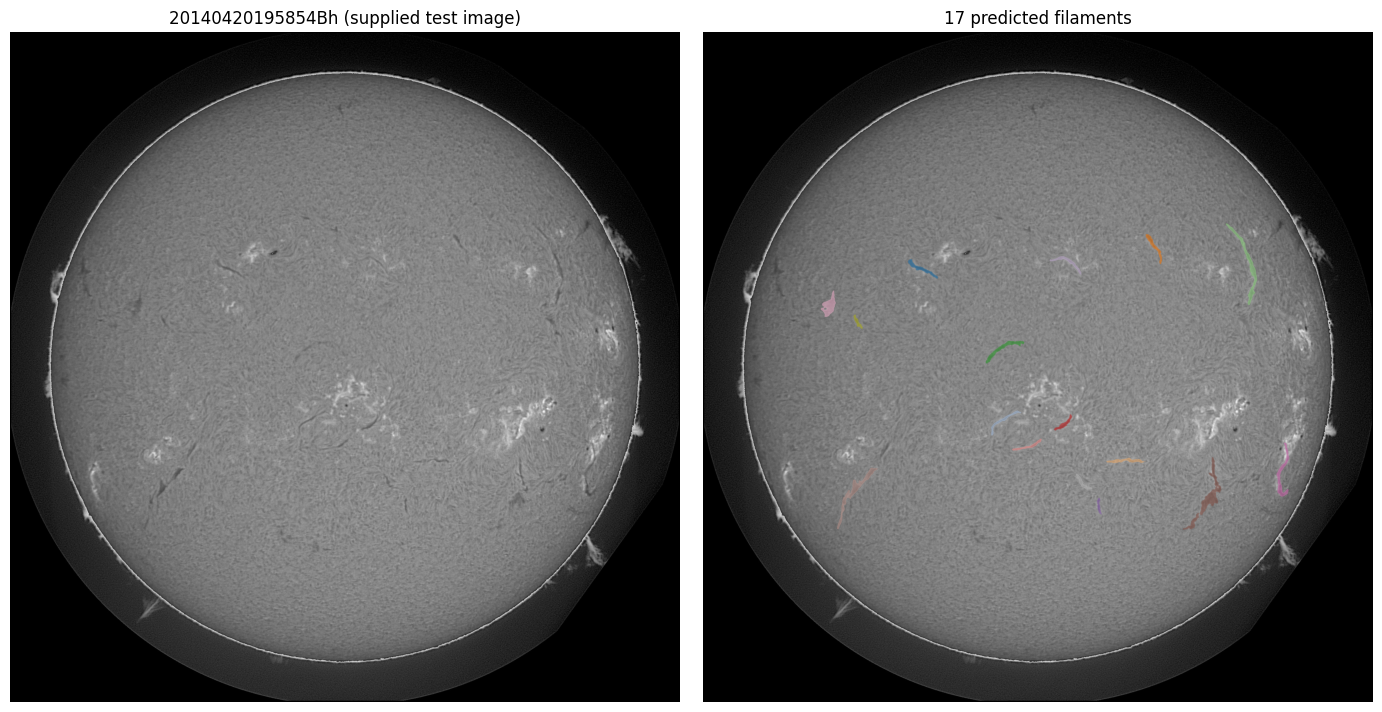

In [9]:
overlay = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
colours = plt.get_cmap('tab20')
for number, rle in enumerate(masks):
    mask = mask_utils.decode(rle).astype(bool)
    overlay[mask] = (0.45 * overlay[mask] + 0.55 * np.array(colours(number % 20)[:3]) * 255).astype(np.uint8)
figure, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(image, cmap='gray'); axes[0].set_title(f'{stem} (supplied test image)')
axes[1].imshow(overlay); axes[1].set_title(f'{len(masks)} predicted filaments')
for axis in axes:
    axis.axis('off')
plt.tight_layout()

## Check against the submitted file

The release includes `submission.csv`, the file Kaggle scored. A different GPU can move a few mask pixels through
mixed-precision arithmetic, so the masks for this image are matched at IoU > 0.5 rather than compared byte for
byte.

In [10]:
from solar_filament.metrics import overlap_matrix
from solar_filament.submission import load_predictions

submitted = load_predictions(WEIGHTS / 'submission.csv').get(stem, [])
best = overlap_matrix(submitted, masks).max(axis=1) if submitted and masks else np.zeros(len(submitted))
matched = best > 0.5
print(f'submitted masks: {len(submitted)} | reproduced: {len(masks)} | matched at IoU > 0.5: {int(matched.sum())}')
print(f'median IoU of matched masks: {np.median(best[matched]) if matched.any() else 0:.4f}')

submitted masks: 17 | reproduced: 17 | matched at IoU > 0.5: 17
median IoU of matched masks: 1.0000


## The full test set

The same stages over all 180 test images rebuild the submitted CSV. The script verifies every released file
against `manifest.json`, resumes stage by stage, and compares the result with the released `submission.csv`:

```
python infra/reproduce-submission.py --weights $SOLAR_STORAGE_ROOT/weights/final \
    --output $SOLAR_STORAGE_ROOT/runs/reproduction
```

On one L40S GPU, the 25 TTA passes take about 50 minutes, and fusion, refinement and level 2 about 20 minutes more
on 8 CPU cores. Training commands for every model are in `configs/` and the README. Out-of-fold PQ for each stage is
in the README and the report.

In [11]:
RUN_FULL_REPRODUCTION = False   # about 70 minutes on one L40S
if RUN_FULL_REPRODUCTION:
    import subprocess
    subprocess.run([sys.executable, 'infra/reproduce-submission.py', '--weights', str(WEIGHTS),
                    '--output', str(root / 'runs' / 'reproduction')], check=True)